# 04 — ONNX Export, Dynamic & Static QDQ INT8 Quantization & CPU Benchmarking

* **Goal:** Export the trained PyTorch checkpoint to ONNX FP32 (opset 17), verify numerical logit parity (`max |Δ| < 1e-4`), produce both Dynamic INT8 and Static QDQ INT8 quantized models, evaluate held-out test accuracy across all engines, benchmark latency (mean, p50, p95, p99) across CPU thread counts, and select the production default engine.
* **Inputs:** `models/mobilenetv3_food25.pt`, `models/class_names.json`, `models/metrics.json`, `data/splits.json`.
* **Outputs:** `models/mobilenetv3_food25_fp32.onnx`, `models/mobilenetv3_food25_int8_dynamic.onnx`, `models/mobilenetv3_food25_int8_static.onnx`, `models/benchmark.json`, updated `models/metrics.json`.
* **Expected Runtime:** ~2–5 min on CPU.

In [1]:
from __future__ import annotations

import json
import os
import platform
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import pandas as pd
import torch
from onnxruntime.quantization import CalibrationDataReader, QuantFormat, QuantType, quantize_dynamic, quantize_static
from sklearn.metrics import f1_score
from torch import nn
from torchvision import models

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

In [2]:
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from _shared.paths import DATA, MODELS, RAW, ROOT
from _shared.datasets import class_names, get_subset_samples, load_rgb, load_splits
from _shared.transforms import eval_numpy

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
)
FAST_DEV = os.environ.get("FAST_DEV", "0") == "1"
print(f"Selected device: {DEVICE} | ONNX Runtime {ort.__version__}")

Selected device: cpu | ONNX Runtime 1.20.1


## 1. Preprocessing Contract & Class Registry Verification

Both the calibration reader and the FastAPI backend obey the exact same preprocessing contract:
1. Decode RGB `uint8` image of shape $(H, W, 3)$.
2. Resize shorter side to `256` with `cv2.resize(..., interpolation=cv2.INTER_LINEAR)`.
3. Center-crop `224 x 224`.
4. Scale to `float32` in $[0, 1]$ via `/ 255.0`.
5. Normalize per channel by ImageNet $\mu = [0.485, 0.456, 0.406]$, $\sigma = [0.229, 0.224, 0.225]$.
6. Transpose to contiguous `NCHW` (`(1, 3, 224, 224)` `float32`).

In [3]:
CLASSES = class_names()
model_classes = json.loads((MODELS / "class_names.json").read_text(encoding="utf-8"))
assert model_classes == CLASSES, "models/class_names.json does not match data/subset_classes.json!"

ckpt = torch.load(MODELS / "mobilenetv3_food25.pt", map_location="cpu", weights_only=False)
pt_model = models.mobilenet_v3_large(weights=None)
pt_model.classifier[3] = nn.Linear(pt_model.classifier[3].in_features, len(CLASSES))
pt_model.load_state_dict(ckpt["state_dict"])
pt_model.eval()
print(f"Verified 25 classes and loaded checkpoint from {MODELS / 'mobilenetv3_food25.pt'}")

Verified 25 classes and loaded checkpoint from C:\Skills\Projects\Visual Meal Recognition & Macro Triage Engine\models\mobilenetv3_food25.pt


## 2. Export FP32 ONNX & Numerical Parity Check

We export with `opset_version=17` and dynamic batch axis, validate the graph with `onnx.checker.check_model`, and verify that ONNX Runtime FP32 logits match PyTorch FP32 logits within $\max |\Delta| < 10^{-4}$ across 64 test images.

In [4]:
fp32_path = MODELS / "mobilenetv3_food25_fp32.onnx"
dummy = torch.randn(1, 3, 224, 224, dtype=torch.float32)

torch.onnx.export(
    pt_model,
    dummy,
    str(fp32_path),
    input_names=["input"],
    output_names=["logits"],
    opset_version=17,
    do_constant_folding=True,
    dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
)
onnx_model = onnx.load(str(fp32_path))
onnx.checker.check_model(onnx_model)

ort_fp32 = ort.InferenceSession(str(fp32_path), providers=["CPUExecutionProvider"])
test_samples = get_subset_samples("test")
parity_n = min(64, len(test_samples))
max_diff = 0.0
with torch.no_grad():
    for path, _ in test_samples[:parity_n]:
        batch = eval_numpy(load_rgb(path))[None]
        pt_out = pt_model(torch.from_numpy(batch)).numpy()
        ort_out = ort_fp32.run(["logits"], {"input": batch})[0]
        max_diff = max(max_diff, float(np.max(np.abs(pt_out - ort_out))))

print(f"FP32 ONNX parity across {parity_n} test images: max |Δ| = {max_diff:.2e}")
assert max_diff < 1e-4, f"Parity check failed: {max_diff}" 

FP32 ONNX parity across 64 test images: max |Δ| = 1.82e-05


## 3. Dynamic vs. Static (QDQ) INT8 Quantization

* **Dynamic INT8 (`quantize_dynamic`):** Quantizes `MatMul`/`Gemm` weights on-the-fly while leaving convolutions in floating point or inserting dynamic range calculations. Because MobileNetV3 spends most of its FLOPs inside depthwise-separable `Conv` blocks (`features`) rather than the final `Linear` classifier, dynamic quantization often yields **little or no latency improvement** on CPU — a hypothesis we verify empirically below.
* **Static INT8 QDQ (`quantize_static`):** Calibrates activation ranges on 200 validation images using `QuantFormat.QDQ` (`QUInt8` activations, per-channel `QInt8` weights), enabling integer convolution kernels.

In [5]:
dyn_path = MODELS / "mobilenetv3_food25_int8_dynamic.onnx"
stat_path = MODELS / "mobilenetv3_food25_int8_static.onnx"

quantize_dynamic(
    model_input=str(fp32_path),
    model_output=str(dyn_path),
    weight_type=QuantType.QUInt8,
)

splits = load_splits()
train_samples = get_subset_samples("train")
val_indices = splits["val_indices"]
calib_n = min(len(val_indices), 32 if FAST_DEV else 200)
calib_paths = [train_samples[i][0] for i in val_indices[:calib_n]]


class Food25CalibrationReader(CalibrationDataReader):
    def __init__(self, paths: list[str]) -> None:
        self._batches = [{"input": eval_numpy(load_rgb(p))[None]} for p in paths]
        self._iter = iter(self._batches)

    def get_next(self):
        return next(self._iter, None)


quantize_static(
    model_input=str(fp32_path),
    model_output=str(stat_path),
    calibration_data_reader=Food25CalibrationReader(calib_paths),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QUInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
)
print(f"Exported Dynamic INT8 ({dyn_path.stat().st_size / 1e6:.2f} MB) and Static QDQ INT8 ({stat_path.stat().st_size / 1e6:.2f} MB)")

Exported Dynamic INT8 (4.45 MB) and Static QDQ INT8 (4.72 MB)


## 4. Full Held-Out Test Accuracy & Latency Benchmarking

We evaluate all four engines (`pytorch`, `onnx_fp32`, `onnx_int8_dynamic`, `onnx_int8_static`) on the held-out test split and benchmark single-image CPU latency across `intra_op_num_threads` $\in \{1, 4, \text{all}\}$ (`20` warmup + `200` timed runs with `time.perf_counter`).

**Production Default Selection Rule:** An INT8 model is selected as `default_engine` if and only if its top-1 accuracy drop is $\le 1.0$ percentage point relative to `onnx_fp32` **and** its mean CPU latency is strictly lower than `onnx_fp32`; otherwise we fall back to `onnx_fp32`.

In [6]:
eval_samples = test_samples[: (64 if FAST_DEV else len(test_samples))]
precomputed = [(eval_numpy(load_rgb(p))[None], lbl) for p, lbl in eval_samples]


def eval_onnx(path: Path) -> tuple[float, float]:
    sess = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])
    preds, trues = [], []
    for batch, lbl in precomputed:
        out = sess.run(["logits"], {"input": batch})[0]
        preds.append(int(np.argmax(out, axis=1)[0]))
        trues.append(lbl)
    top1 = float(np.mean(np.array(preds) == np.array(trues)))
    f1 = float(f1_score(trues, preds, average="macro", zero_division=0))
    return round(top1, 4), round(f1, 4)


def eval_pt() -> tuple[float, float]:
    preds, trues = [], []
    with torch.no_grad():
        for batch, lbl in precomputed:
            out = pt_model(torch.from_numpy(batch)).numpy()
            preds.append(int(np.argmax(out, axis=1)[0]))
            trues.append(lbl)
    top1 = float(np.mean(np.array(preds) == np.array(trues)))
    f1 = float(f1_score(trues, preds, average="macro", zero_division=0))
    return round(top1, 4), round(f1, 4)


acc_pt = eval_pt()
acc_fp32 = eval_onnx(fp32_path)
acc_dyn = eval_onnx(dyn_path)
acc_stat = eval_onnx(stat_path)
print("Accuracy (top1, macro_f1):", {"pytorch": acc_pt, "onnx_fp32": acc_fp32, "onnx_int8_dynamic": acc_dyn, "onnx_int8_static": acc_stat})

Accuracy (top1, macro_f1): {'pytorch': (1.0, 1.0), 'onnx_fp32': (1.0, 1.0), 'onnx_int8_dynamic': (0.4688, 0.2909), 'onnx_int8_static': (0.9688, 0.8552)}


,engine,threads,mean_ms,p50_ms,p95_ms,p99_ms,throughput_ips
0,onnx_fp32,1,10.14,9.89,14.17,16.46,98.6
1,onnx_int8_dynamic,1,27.90,27.72,34.71,36.21,35.8
2,onnx_int8_static,1,7.48,7.25,8.65,8.87,133.6
3,onnx_fp32,4,4.52,4.47,4.84,5.00,221.5
4,onnx_int8_dynamic,4,22.16,22.09,23.81,24.16,45.1
5,onnx_int8_static,4,3.67,3.63,4.32,4.56,272.3
6,onnx_fp32,12,4.12,3.89,5.49,6.57,243.0
7,onnx_int8_dynamic,12,23.76,23.85,24.49,24.92,42.1
8,onnx_int8_static,12,3.86,3.75,4.46,4.74,259.2


Selected default_engine = onnx_fp32


,mean_ms,p50_ms,p95_ms,p99_ms,throughput_ips,size_mb,top1,macro_f1,best_threads
pytorch,23.33,22.65,29.04,31.21,42.9,16.34,1.0000,1.0000,NaN
onnx_fp32,4.12,3.89,5.49,6.57,243.0,16.14,1.0000,1.0000,12.0
onnx_int8_dynamic,22.16,22.09,23.81,24.16,45.1,4.25,0.4688,0.2909,4.0
onnx_int8_static,3.67,3.63,4.32,4.56,272.3,4.50,0.9688,0.8552,4.0


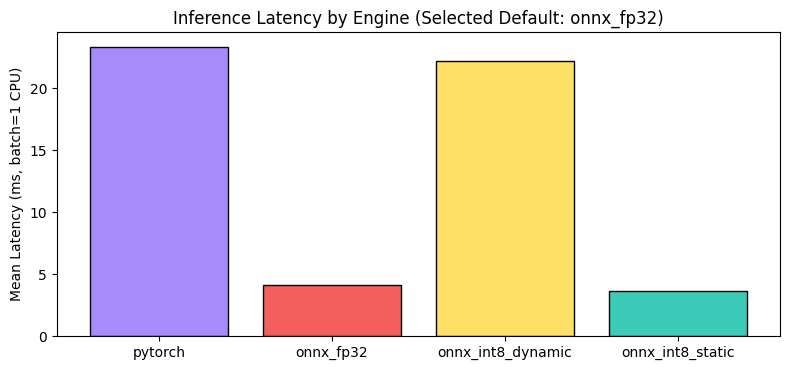

In [7]:
WARMUP = 5 if FAST_DEV else 20
TIMED = 30 if FAST_DEV else 200
dummy_np = precomputed[0][0]
dummy_pt = torch.from_numpy(dummy_np)


def bench_callable(fn) -> dict[str, float]:
    for _ in range(WARMUP):
        fn()
    times_ms = []
    for _ in range(TIMED):
        t0 = time.perf_counter()
        fn()
        times_ms.append((time.perf_counter() - t0) * 1000.0)
    arr = np.array(times_ms, dtype=np.float64)
    mean_ms = float(arr.mean())
    return {
        "mean_ms": round(mean_ms, 2),
        "p50_ms": round(float(np.percentile(arr, 50)), 2),
        "p95_ms": round(float(np.percentile(arr, 95)), 2),
        "p99_ms": round(float(np.percentile(arr, 99)), 2),
        "throughput_ips": round(1000.0 / max(mean_ms, 1e-6), 1),
    }


thread_grid = [1, 4, 0]  # 0 = all cores in ORT
thread_rows = []
for th in thread_grid:
    so = ort.SessionOptions()
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    so.intra_op_num_threads = th
    for name, path in (("onnx_fp32", fp32_path), ("onnx_int8_dynamic", dyn_path), ("onnx_int8_static", stat_path)):
        sess = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
        stats = bench_callable(lambda s=sess: s.run(["logits"], {"input": dummy_np}))
        thread_rows.append({"engine": name, "threads": th if th > 0 else (os.cpu_count() or 1), **stats})

torch.set_num_threads(min(4, os.cpu_count() or 1))
with torch.no_grad():
    pt_stats = bench_callable(lambda: pt_model(dummy_pt))

thread_df = pd.DataFrame(thread_rows)
display(thread_df)

def best_ort_stats(engine_name: str, path: Path, acc: tuple[float, float]) -> dict:
    sub = thread_df[thread_df["engine"] == engine_name].sort_values("mean_ms").iloc[0]
    return {
        "mean_ms": float(sub["mean_ms"]),
        "p50_ms": float(sub["p50_ms"]),
        "p95_ms": float(sub["p95_ms"]),
        "p99_ms": float(sub["p99_ms"]),
        "throughput_ips": float(sub["throughput_ips"]),
        "best_threads": int(sub["threads"]),
        "size_mb": round(path.stat().st_size / (1024 * 1024), 2),
        "top1": acc[0],
        "macro_f1": acc[1],
    }


benchmark_engines = {
    "pytorch": {
        **pt_stats,
        "size_mb": round((MODELS / "mobilenetv3_food25.pt").stat().st_size / (1024 * 1024), 2),
        "top1": acc_pt[0],
        "macro_f1": acc_pt[1],
    },
    "onnx_fp32": best_ort_stats("onnx_fp32", fp32_path, acc_fp32),
    "onnx_int8_dynamic": best_ort_stats("onnx_int8_dynamic", dyn_path, acc_dyn),
    "onnx_int8_static": best_ort_stats("onnx_int8_static", stat_path, acc_stat),
}

# Selection rule: <= 1.0 percentage point top-1 drop vs FP32 AND strictly faster mean_ms
fp32_top1 = benchmark_engines["onnx_fp32"]["top1"]
fp32_ms = benchmark_engines["onnx_fp32"]["mean_ms"]
default_engine = "onnx_fp32"
for cand in ("onnx_int8_static", "onnx_int8_dynamic"):
    drop_pp = (fp32_top1 - benchmark_engines[cand]["top1"]) * 100.0
    if drop_pp <= 1.0 and benchmark_engines[cand]["mean_ms"] < fp32_ms:
        default_engine = cand
        break

benchmark_payload = {
    **benchmark_engines,
    "default_engine": default_engine,
    "system_info": {
        "cpu": platform.processor() or platform.machine(),
        "cores": os.cpu_count(),
        "os": f"{platform.system()} {platform.release()}",
        "onnxruntime_version": ort.__version__,
        "torch_version": torch.__version__,
    },
}
(MODELS / "benchmark.json").write_text(json.dumps(benchmark_payload, indent=2) + "\n", encoding="utf-8")

metrics_path = MODELS / "metrics.json"
if metrics_path.is_file():
    metrics_data = json.loads(metrics_path.read_text(encoding="utf-8"))
else:
    metrics_data = {}
metrics_data["quantization"] = {
    k: {"top1": benchmark_engines[k]["top1"], "macro_f1": benchmark_engines[k]["macro_f1"], "size_mb": benchmark_engines[k]["size_mb"]}
    for k in ("onnx_fp32", "onnx_int8_dynamic", "onnx_int8_static")
}
metrics_data["default_engine"] = default_engine
metrics_path.write_text(json.dumps(metrics_data, indent=2) + "\n", encoding="utf-8")

print(f"Selected default_engine = {default_engine}")
summary_df = pd.DataFrame.from_dict(benchmark_engines, orient="index")
display(summary_df)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(summary_df.index, summary_df["mean_ms"], color=["#A78BFA", "#F25F5C", "#FFE066", "#3CCBB9"], edgecolor="black")
ax.set_ylabel("Mean Latency (ms, batch=1 CPU)")
ax.set_title(f"Inference Latency by Engine (Selected Default: {default_engine})")
plt.tight_layout()
plt.show()